# 3.7 - ARIMA-GARCH timing of the S&P 500

A **market-timing** strategy: each day it is either long or short the S&P 500, as a time-series model of the index's
recent returns forecasts the next day's return to be positive or negative. It reproduces the strategy in
[`menonf/PythonProjects/TimeSeries/strategy_single_core_CPU`](https://github.com/menonf/PythonProjects/tree/master/TimeSeries/strategy_single_core_CPU)
(`ARIMAGARCHStrategy.py`, with `PyModules.evaluate_models`) on our data, backtests it with trading costs and
registers the run.

**The two models.**

* **ARIMA(p, d, q)** - an autoregressive integrated moving-average model of the mean. The series is differenced *d*
  times; the result is regressed on its own *p* previous values (the AR part) and on the *q* previous forecast errors
  (the MA part): $\Delta^d y_t = \sum_{i=1}^{p} \phi_i \Delta^d y_{t-i} + \varepsilon_t + \sum_{j=1}^{q} \theta_j
  \varepsilon_{t-j}$. The order is chosen by the **Akaike information criterion**, $\text{AIC} = 2k - 2\ln L$ - the
  fit's log-likelihood penalised for its *k* parameters.
* **GARCH(p, o, q)** - generalised autoregressive conditional heteroskedasticity (Bollerslev, 1986): a model of the
  *variance* of returns, in which today's variance depends on yesterday's squared shock and yesterday's variance, so
  that volatile days cluster. With $o = 1$ it is the **GJR-GARCH** of Glosten, Jagannathan and Runkle (1993), whose
  extra term lets a negative shock raise volatility more than a positive one:
  $\sigma_t^2 = \omega + \alpha \varepsilon_{t-1}^2 + \gamma \varepsilon_{t-1}^2 \mathbb{1}[\varepsilon_{t-1} < 0] +
  \beta \sigma_{t-1}^2$, with $r_t = \mu + \varepsilon_t$.

**The rules** (the script's settings, all in `ArimaGarchConfig`):

| Step | Rule |
|---|---|
| Data | daily log returns of the S&P 500 index (^GSPC), $\ln(P_t / P_{t-1})$ |
| Window | the 24 returns up to and including day *t*, re-fitted every day (the script's `RollingWindowLength = 25` slices 24) |
| Mean model | every ARIMA(p, 1, q) with p and q from 1 to 5 - 25 models - fitted by maximum likelihood; the lowest AIC is kept |
| Volatility model | a GJR-GARCH(1, 1, 1) with a constant mean, fitted to that ARIMA's residuals (its asymmetric order *o* is the ARIMA's *d*, as in the script) |
| Signal | the sign of the GARCH model's one-step forecast of the mean: +1 long, -1 short |
| Trading | the position is taken at day *t*'s close and held over day *t + 1* - no look-ahead |

**Differences from the script:**

* **Sample period.** The script ran on the S&P 500's last three years (to its own date). Ours are the three years
  before our hold-out, **3 January 2022 to 31 December 2024**; the hold-out (2025 on) stays closed.
* **What is earned.** The script scored the strategy as the cumulative *sum* of signal x log return of the index, plus
  one. A position held in a fund earns *simple* returns, compounded, and the index itself cannot be bought. So the
  position is held in **SPY** (the S&P 500 ETF, dividends included), with a cost of 1 basis point per unit traded -
  a switch from long to short trades two units. The script's own measure is shown as well.
* **Failed fits.** The script's `except e:` would itself fail if an ARIMA fit raised an error; here an order that
  cannot be fitted is passed over, and a day on which nothing fits is flat. Model warnings are silenced.

**Computation.** 25 ARIMA fits a day take about 8 seconds on one core - about 100 minutes for three years. Each day's
models are stored (`data/<database>/research/arima_garch/`) with a digest of the returns they were fitted to, so the
notebook re-runs in seconds, and a stopped run resumes where it left off.


In [1]:
import numpy as np
import pandas as pd
from IPython.display import display

from equity_research import charts
from equity_research.db.engine import get_engine
from equity_research.research.arima_garch import ArimaGarchConfig, run_arima_garch, script_view, signal_diagnostics
from equity_research.research.backtest import performance
from equity_research.research.cache import ResearchCache
from equity_research.research.indices import calendar_years, vendor_returns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

charts.style()
cache = ResearchCache()
engine = get_engine()
config = ArimaGarchConfig()  # the script's settings; any change is a variant and a new registered trial


def progress(fitted: int, to_fit: int) -> None:  # noqa: D103 - reports every 50th day (the first run takes ~100 minutes)
    if fitted % 50 == 0 or fitted == to_fit:
        print(f"{fitted} of {to_fit} days fitted")


result = run_arima_garch(cache, config, engine=engine, progress=progress)
net, gross, spy = result.backtest.net, result.backtest.gross, result.benchmark
print("Registered as research run", result.run_id, "- trials of this family so far:", result.metrics["trials"])
first, last = result.forecasts.index.min(), result.forecasts.index.max()
print(f"{len(result.forecasts)} days forecast, {first:%d %b %Y} to {last:%d %b %Y}")

Registered as research run 119 - trials of this family so far: 1
753 days forecast, 03 Jan 2022 to 31 Dec 2024


## Performance

The strategy before and after trading costs, against holding SPY throughout. **Sharpe ratio**: the annualised mean
daily return over its annualised standard deviation (no risk-free rate). **Maximum drawdown**: the largest fall from a
previous peak. Against SPY: **beta** (the strategy's sensitivity to SPY's returns), **alpha** (its return beyond what
that beta explains), **tracking error** (the volatility of the return difference) and the **information ratio**
(active return over tracking error). The **deflated Sharpe ratio** (Bailey and Lopez de Prado, 2014) is the
probability that the true Sharpe ratio is above zero once the number of variants tried in this family is allowed for.


,cagr,vol,sharpe,max_drawdown
"ARIMA-GARCH, net of costs",-0.2%,17.5%,0.08,-25%
"ARIMA-GARCH, before costs",1.2%,17.5%,0.15,-23%
SPY held throughout,8.7%,17.5%,0.56,-24%


,beta,alpha,active_return,tracking_error,information_ratio,turnover,deflated_sharpe
ARIMA-GARCH against SPY,0.14,-0.1%,-8.1%,22.6%,-0.38,138,55%


,ARIMA-GARCH,SPY,ahead of SPY
trade_date,,,
2022,+15.7%,-18.6%,+34.3%
2023,-6.0%,+26.2%,-32.2%
2024,-8.6%,+24.9%,-33.5%


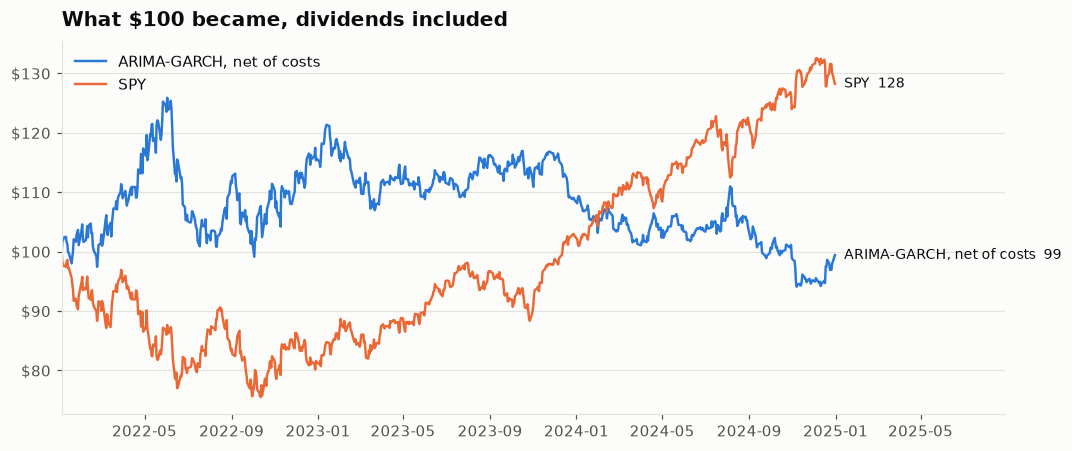

In [2]:
PERF = {"cagr": "{:.1%}", "vol": "{:.1%}", "sharpe": "{:.2f}", "max_drawdown": "{:.0%}"}
lines = {"ARIMA-GARCH, net of costs": net, "ARIMA-GARCH, before costs": gross, "SPY held throughout": spy}
display(pd.DataFrame({name: performance(r) for name, r in lines.items()}).T.style.format(PERF))
m = result.metrics
ACTIVE = {
    "beta": "{:.2f}",
    "alpha": "{:+.1%}",
    "active_return": "{:+.1%}",
    "tracking_error": "{:.1%}",
    "information_ratio": "{:+.2f}",
    "turnover": "{:.0f}",
    "deflated_sharpe": "{:.0%}",
}
display(pd.DataFrame({"ARIMA-GARCH against SPY": {k: m[k] for k in ACTIVE}}).T.style.format(ACTIVE))
fig = charts.growth({"ARIMA-GARCH, net of costs": net, "SPY": spy}, "What $100 became, dividends included", log=False)
years = calendar_years({"ARIMA-GARCH": net, "SPY": spy})
years["ahead of SPY"] = years["ARIMA-GARCH"] - years["SPY"]
display(years.style.format("{:+.1%}"))

## The script's own measure

The script plotted $1 + \sum_t s_{t-1} \ln(P_t / P_{t-1})$ for the strategy and $1 + \sum_t \ln(P_t / P_{t-1})$ for
buy-and-hold, on the index's prices without dividends. The same lines on our period, for comparison with the script's
chart - the shape matches the backtest above; the levels differ because log returns are summed, not compounded.


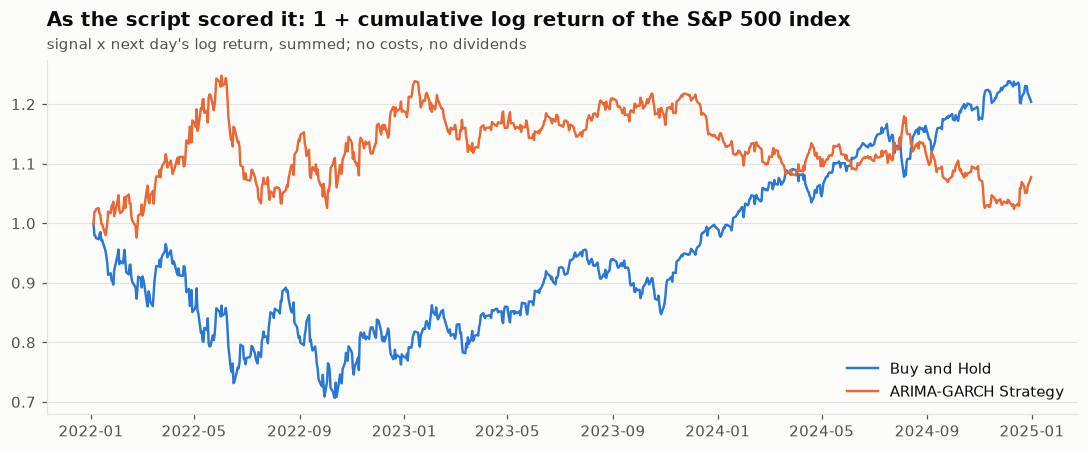

In [3]:
logs = np.log1p(vendor_returns(cache, config.signal_symbol, total=False))
view = script_view(result.forecasts["signal"], logs)
fig = charts.lines(
    {name: view[name] for name in view.columns},
    "As the script scored it: 1 + cumulative log return of the S&P 500 index",
    subtitle="signal x next day's log return, summed; no costs, no dividends",
)

## Does the signal forecast the next day?

The **hit rate** is the share of days on which the position had the sign of the next day's return. It has to be
judged against chance: a signal with no information that is long a fraction *L* of the days, in a market that rises
on a fraction *U* of them, is right $L U + (1 - L)(1 - U)$ of the time. The **z-statistic** compares the hit rate with
that rate, $z = (\hat h - h_0) / \sqrt{h_0 (1 - h_0) / n}$; $|z| < 2$ cannot be told apart from chance at the 5 %
level. Below it: how often each ARIMA order was chosen, and the share of each month's days spent long.


,value
days forecast,753
share of days long,44.5%
share of days short,55.5%
share of days flat (no model fitted),0.0%
position changes a year,68
hit rate,50.9%
SPY's up days,52.8%
hit rate of chance,49.7%
z-statistic against chance,+0.68


Share of days each ARIMA(p, 1, q) had the lowest AIC:


MA order q,1,2,3,4,5
AR order p,,,,,
1,56%,7%,6%,4%,1%
2,13%,3%,1%,1%,0%
3,2%,1%,1%,0%,0%
4,2%,1%,0%,0%,0%
5,1%,0%,0%,0%,0%


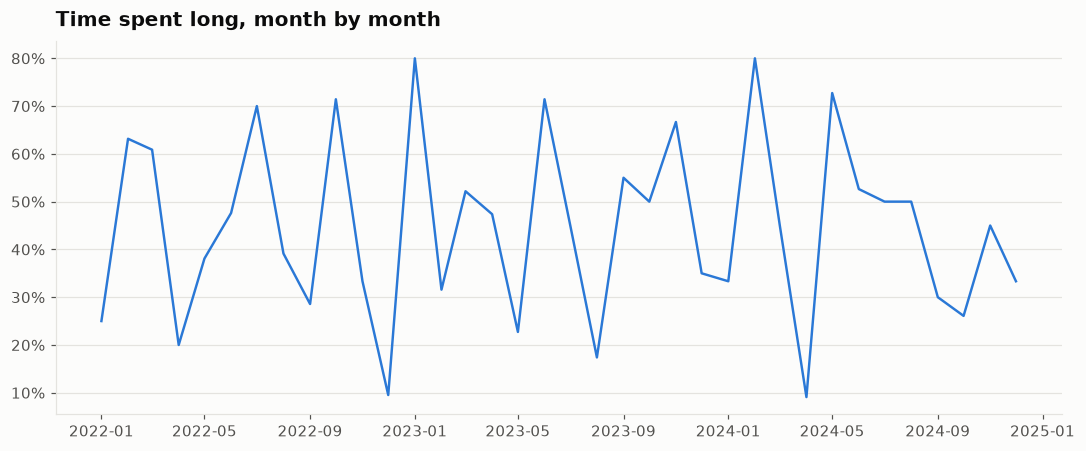

In [4]:
d = signal_diagnostics(result.forecasts, spy)
SHOW = {
    "days": ("days forecast", "{:,.0f}"),
    "long": ("share of days long", "{:.1%}"),
    "short": ("share of days short", "{:.1%}"),
    "flat": ("share of days flat (no model fitted)", "{:.1%}"),
    "changes_per_year": ("position changes a year", "{:.0f}"),
    "hit_rate": ("hit rate", "{:.1%}"),
    "up_days": ("SPY's up days", "{:.1%}"),
    "chance_hit_rate": ("hit rate of chance", "{:.1%}"),
    "hit_z": ("z-statistic against chance", "{:+.2f}"),
}
display(
    pd.DataFrame({"value": [fmt.format(d[k]) for k, (_, fmt) in SHOW.items()]}, index=[n for n, _ in SHOW.values()])
)
f = result.forecasts
orders = f[f["p"] > 0].pivot_table(index="p", columns="q", values="signal", aggfunc="size", fill_value=0)
orders.index.name, orders.columns.name = "AR order p", "MA order q"
print("Share of days each ARIMA(p, 1, q) had the lowest AIC:")
display((orders / orders.to_numpy().sum()).style.format("{:.0%}"))
fig = charts.lines(
    {"share of the month's days long": (f["signal"] > 0).groupby(f.index.to_period("M")).mean().to_timestamp()},
    "Time spent long, month by month",
    percent=True,
)

## What the signal really is

In the script the GARCH model is `arch_model(resid, p=1, o=d, q=1)`, whose default mean model is a **constant**:
$r_t = \mu + \varepsilon_t$. A constant-mean model forecasts $\mu$ at every horizon, so the signal is the sign of
$\hat\mu$, the GARCH model's estimate of the mean of the ARIMA residuals - roughly their average over the 24-day
window. The ARIMA model's own forecast of the next return never reaches the position; the ARIMA stage matters only
through the residuals it leaves. The table compares the three on every day: how often $\hat\mu$ has the sign of the
residuals' plain average, and how often it has the sign of the ARIMA forecast.


In [5]:
agree = pd.Series(
    {
        "sign of mu = sign of the residuals' average": d["mu_sign_matches_resid_mean"],
        "sign of mu = sign of the ARIMA forecast": d["mu_sign_matches_arima_forecast"],
    }
)
display(agree.to_frame("share of days").style.format("{:.1%}"))
print("The last ten days' models:")
display(f[["p", "q", "aic", "arima_forecast", "resid_mean", "mean_forecast", "signal"]].tail(10))

,share of days
sign of mu = sign of the residuals' average,88.6%
sign of mu = sign of the ARIMA forecast,56.4%


The last ten days' models:


,p,q,aic,arima_forecast,resid_mean,mean_forecast,signal
trade_date,,,,,,,
2024-12-17,2,2,-170.9,0.002184,5.3e-05,-0.0003662,-1
2024-12-18,1,1,-148.7,-0.01364,-0.0009855,0.0003195,1
2024-12-19,1,1,-148.8,-0.004461,-0.0004804,0.000821,1
2024-12-20,1,3,-152.6,-0.009357,-0.001654,-0.001425,-1
2024-12-23,1,1,-148.7,0.00103,-0.001079,-0.000885,-1
2024-12-24,1,1,-147.6,0.002748,-0.0004753,-0.0005716,-1
2024-12-26,1,1,-147.6,0.0006441,-0.001047,-0.001183,-1
2024-12-27,1,1,-145.9,-0.001854,-0.001247,-0.001326,-1
2024-12-30,1,1,-145.1,-0.002905,-0.001414,-0.001484,-1


## Findings

* **The strategy did not beat holding SPY.** From January 2022 to December 2024 it returned -0.2 % a year after costs
  (1.2 % before) against SPY's 8.7 %, with the same volatility (17.5 %) and a similar maximum drawdown (-25 % against
  -24 %): a Sharpe ratio of 0.08 against 0.56. Its beta to SPY is 0.14 - being long and short in about equal measure,
  it carries little of the market - so its active return of -8.1 % a year is mostly the market return it gave up.
* **One good year, two bad ones.** It gained 15.7 % in 2022, when SPY fell 18.6 %: the signal was short on 55.5 % of all
  days, and in a falling year that bias pays. When the market rose it lost: -6.0 % in 2023 and -8.6 % in 2024, against
  SPY's +26.2 % and +24.9 %. The chart shows the strategy ahead until early 2024 and behind from then on.
* **The signal has no measurable forecasting power.** Its positions had the sign of the next day's return on 50.9 % of
  days; a signal with no information, long as often as this one in a market up on 52.8 % of days, would be right on
  49.7 %. The z-statistic of +0.68 is well inside chance. The deflated Sharpe ratio is 55 % - with a single trial in
  the family, simply the probability that the true Sharpe ratio is above zero, far from the 95 % that would convince.
* **Costs matter at this turnover.** The position changes 68 times a year; each change trades two units of SPY, so the
  book trades 138 times its value a year, and even 1 basis point a unit traded costs 1.4 points of return a year.
* **The model choice is mostly the simplest.** ARIMA(1, 1, 1) has the lowest AIC on 56 % of days and ARIMA(2, 1, 1) on
  13 %; with 24 observations the AIC penalty rules out the larger models almost always.
* **The position follows the GARCH model's constant mean, not the ARIMA forecast.** The sign of the GARCH mean
  estimate matches the sign of the ARIMA residuals' average on 88.6 % of days, but the sign of the ARIMA model's own
  forecast on only 56.4 %. As specified in the script, the strategy is a bet on the sign of the recent average
  residual of an over-differenced series (returns differenced once more), not on the ARIMA forecast.

**What would be worth testing next** (each a new registered trial in the family): the position from the ARIMA
forecast itself, with GARCH used to size it or to stand aside when forecast volatility is high; ARIMA on returns
without the extra difference (d = 0); and a longer window than 24 days, which gives the models enough data to estimate
more than two or three parameters.

## Glossary

* **Log return** - $\ln(P_t / P_{t-1})$; log returns add over time, simple returns $P_t / P_{t-1} - 1$ compound.
* **Stationary** - a series whose mean and variance do not change over time; differencing (*d*) makes a trending
  series stationary. Daily returns are already close to stationary, so the script's $d = 1$ differences them again.
* **Maximum likelihood** - the parameters under which the observed data are most probable.
* **AIC** - Akaike information criterion: $2k - 2 \ln L$; lower is better, and each parameter must earn its place.
* **GARCH / GJR-GARCH** - models of time-varying volatility; GJR adds a larger response to negative shocks.
* **Look-ahead bias** - using information not yet available at the decision; here the window ends at the close on
  which the position is taken.
* **Hit rate** - the share of days the position's sign matched the next day's return.
* **Sharpe ratio, information ratio, deflated Sharpe ratio** - see notebook 3.2.
